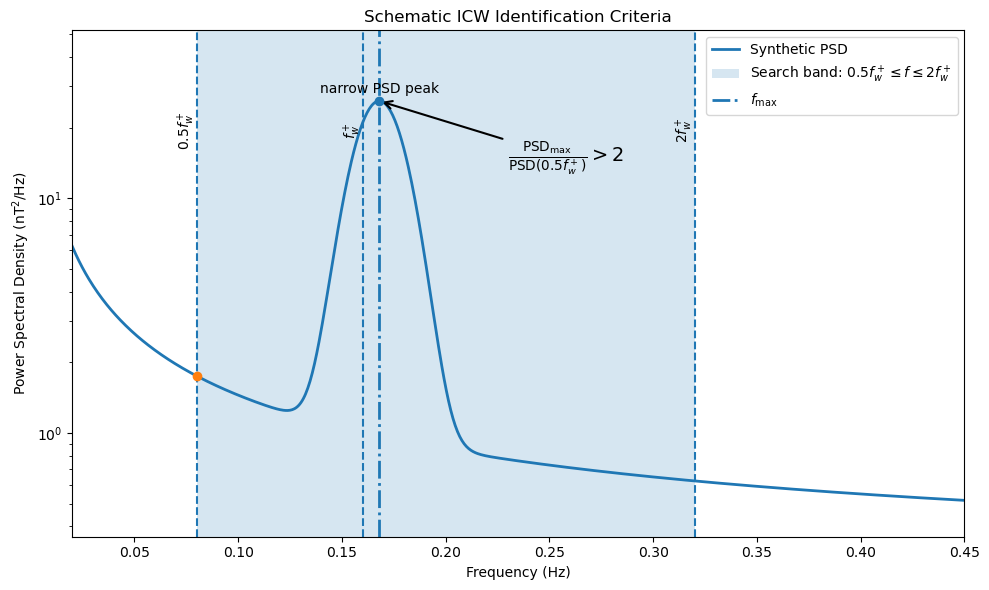

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Fake PSD data for ICW criteria
# -----------------------------

# Frequency axis
f = np.linspace(0.02, 0.45, 800)

# Define H2O+ gyrofrequency
f_w = 0.16  # Hz, example value

# Search band used in literature
f_low = 0.5 * f_w
f_high = 2.0 * f_w

# Fake background + narrow ICW peak
background = 0.25 + 0.12 / f
peak_center = 1.05 * f_w
peak_width = 0.012
peak = 25 * np.exp(-0.5 * ((f - peak_center) / peak_width)**2)

# Total PSD
psd = background + peak

# Find maximum PSD inside search band
band_mask = (f >= f_low) & (f <= f_high)
f_max = f[band_mask][np.argmax(psd[band_mask])]
psd_max = np.max(psd[band_mask])
psd_low = np.interp(f_low, f, psd)

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(10, 6))

plt.plot(f, psd, linewidth=2, label="Synthetic PSD")

# Highlight search band
plt.axvspan(f_low, f_high, alpha=0.18, label=r"Search band: $0.5f_w^+ \leq f \leq 2f_w^+$")

# Mark important frequencies
plt.axvline(f_low, linestyle="--", linewidth=1.5)
plt.axvline(f_w, linestyle="--", linewidth=1.5)
plt.axvline(f_high, linestyle="--", linewidth=1.5)
plt.axvline(f_max, linestyle="-.", linewidth=2, label=r"$f_{\max}$")

# Annotate frequency markers
plt.text(f_low, max(psd)*0.75, r"$0.5f_w^+$", rotation=90, va="center", ha="right")
plt.text(f_w, max(psd)*0.75, r"$f_w^+$", rotation=90, va="center", ha="right")
plt.text(f_high, max(psd)*0.75, r"$2f_w^+$", rotation=90, va="center", ha="right")
plt.text(f_max, psd_max*1.08, r"narrow PSD peak", ha="center")

# Annotate power ratio criterion
plt.scatter([f_max], [psd_max], zorder=5)
plt.scatter([f_low], [psd_low], zorder=5)

plt.annotate(
    r"$\frac{\mathrm{PSD}_{\max}}{\mathrm{PSD}(0.5f_w^+)} > 2$",
    xy=(f_max, psd_max),
    xytext=(0.23, psd_max * 0.55),
    arrowprops=dict(arrowstyle="->", linewidth=1.5),
    fontsize=14
)

# Labels
plt.xlabel("Frequency (Hz)")
plt.ylabel(r"Power Spectral Density (nT$^2$/Hz)")
plt.title("Schematic ICW Identification Criteria")

plt.yscale("log")
plt.xlim(0.02, 0.45)
plt.ylim(min(psd)*0.7, max(psd)*2)

plt.legend(
    # loc=(0.2,1.2), 
           frameon=True)
plt.tight_layout()

plt.savefig("synthetic_icw_psd_criteria.png", dpi=300)
plt.show()